In [1]:
from em1d.transforms import *
from em1d import constants as c
from em1d.physics import refl_transverse_electric as rte
from em1d.physics import freespace_u0
from em1d.experiment import *

In [91]:
class LaplaceHankel:
    def __init__(self, source, receiver, times):
        self.tx = source
        self.rx = receiver
        self.rmin = self.tx.min_horizontal_distance(self.rx)
        self.rmax = self.tx.max_horizontal_distance(self.rx)

        self.times = times
        self.tmin = torch.tensor(self.times.min(), dtype=torch.float64)
        self.tmax = torch.tensor(self.times.max(), dtype=torch.float64)

    def forward(self):
        def wavelength_integrand(wavelength):
            lmb = wavelength[None, :, None]
            def s_integrand(s):
                omega = -1j*s[None, None, :]
                u0 = freespace_u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                intg = cRTE*lmb**2 / u0
                return intg / s
            ift = invLaplace(s_integrand, n_coefficients=8)
            return ift(self.times).squeeze() / c.fourpi
        hkl = Hankel(wavelength_integrand, 1, range=(self.rmin, self.rmax), tolerance=1e-4)
        return integrate_around_loop(self.tx, self.rx, hkl).real

    def __call__(self, sigma, thick):    
        self.sigma = (sigma+0j)[:, None,None]
        self.thick = (thick+0j)[:, None,None]
        return self.forward()

In [92]:
import torch
t = torch.logspace(-7, -1, 51, dtype=torch.float64)
sigma = torch.tensor([1e-2, 1e-2])
thick = torch.tensor([40])

tx = Loop.circle(40)
m = tx.area

rx = Receiver()

fwrLH = LaplaceHankel(tx, rx, t)
dhdt_LH = fwrLH(sigma, thick)

dhdt_lim = (m/20)*(sigma[0]*c.mu0/c.pi)**(3/2) * t**(-5/2)
hz_lim = sigma[0]**(3/2)*c.mu0**(3/2)*40**2 / (30*c.sqrt_pi) * t**(-3/2)

fwrHH = Forward(tx, rx, t)
dhdt_HH = fwrHH(sigma, thick) / c.mu0

C:\Users\au646858\AppData\Local\Temp\ipykernel_31844\3740858527.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.tmin = torch.tensor(self.times.min(), dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_31844\3740858527.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.tmax = torch.tensor(self.times.max(), dtype=torch.float64)


In [93]:
%%timeit
dhdt_LH = fwrLH(sigma, thick)

52.9 ms ± 1.96 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [94]:
%%timeit
dhdt_HH = fwrHH(sigma, thick)

175 ms ± 9.87 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


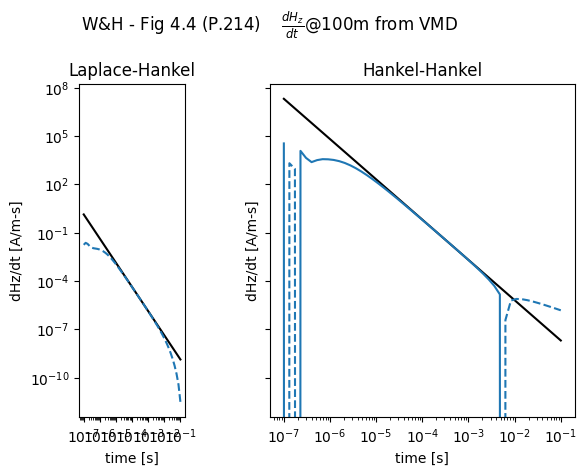

In [98]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(1,2, sharex=True, sharey=True)

axs[0].loglog(fwrLH.times.numpy(), hz_lim.numpy(), 'k')
axs[1].loglog(fwrLH.times.numpy(), dhdt_lim.numpy(), 'k')

axs[0].loglog(fwrLH.times.numpy(),  dhdt_LH.numpy())
axs[0].loglog(fwrLH.times.numpy(), -dhdt_LH.numpy(), 'C0--')
axs[1].loglog(fwrHH.times.numpy(),  dhdt_HH.numpy())
axs[1].loglog(fwrHH.times.numpy(), -dhdt_HH.numpy(), 'C0--')

for ax in axs:
    ax.set_xlabel('time [s]')
    ax.set_ylabel('dHz/dt [A/m-s]')
fig.suptitle('W&H - Fig 4.4 (P.214) \t $\\frac{dH_z}{dt}$@100m from VMD')
axs[0].set_title('Laplace-Hankel')
axs[1].set_title('Hankel-Hankel')
axs[0].set_aspect('equal')
plt.tight_layout()